# 가우시안 프로세스 회귀 실험 노트북
전력사용량 예측 프로젝트, 가우시안 파트 (송이)

이 노트북은 `source_code_file/3_gaussian_model.py`에 있는 실험을 **단계별로 따라가며 눈으로 확인**하기 위한 것이다.
- 1~4절: 데이터 → 입력 만들기 → 모델 학습 → 검증을 **건물 1동**으로 직접 돌려본다 (수십 초)
- 5절: **건물유형 1개**를 돌린다 (몇 분)
- 6절: 이미 돌려 둔 **100동 결과 파일**을 읽어 v1 / v2 비교 그래프를 그린다
- 7절: 추세 처리 방식 3가지 비교 결과

전체 100동 재학습은 `python 3_gaussian_model.py all`로 터미널에서 돌리는 게 낫다 (1시간 이상).

> 노트북은 `source_code_file/` 폴더 안에 있어야 데이터 경로가 맞는다.

In [1]:
import warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import importlib.util
from pathlib import Path

plt.rcParams["font.family"] = "AppleGothic"   # 윈도우면 "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings("ignore")

# 3_gaussian_model.py 의 함수들을 그대로 불러온다 (파일 이름이 숫자로 시작해 import 대신 이렇게 읽음)
spec = importlib.util.spec_from_file_location("gm", "3_gaussian_model.py")
gm = importlib.util.module_from_spec(spec); spec.loader.exec_module(gm)

PROJECT = Path(".").resolve().parent
print("프로젝트 폴더:", PROJECT)
print("입력 변수 (v2):", gm.feature_columns("none"))

프로젝트 폴더: /Users/songi/Desktop/머신러닝/data_file 2
입력 변수 (v2): ['temperature', 'precipitation', 'wind_speed', 'humidity', 'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 'is_off_day']


## 1. 데이터 읽기
팀에서 전처리해 둔 건물유형별 CSV를 읽는다. 아파트부터.

In [2]:
TYPE = "apartment"       # 바꿔서 실험: commercial, department_store, hospital, hotel, idc, other, public, research, school
train_raw, test_raw = gm.load_type(TYPE)
print("train", train_raw.shape, "| test", test_raw.shape)
print("건물번호:", sorted(train_raw.building_id.unique()))
train_raw.head()

train (18360, 18) | test (1512, 15)
건물번호: [np.int64(11), np.int64(25), np.int64(31), np.int64(65), np.int64(70), np.int64(71), np.int64(85), np.int64(91), np.int64(93)]


,num_date_time,building_id,temperature,precipitation,wind_speed,humidity,sunshine,solar_radiation,power_consumption,month,weekday,hour,building_type,total_area,cooling_area,solar_capacity,ess_capacity,pcs_capacity
0,11_20240601 00,11,17.4,0.0,2.7,60.0,0.0,0.0,784.44,6,5,0,아파트,271233.0,233263.0,0.0,0.0,0.0
1,11_20240601 01,11,17.4,0.0,2.6,59.0,0.0,0.0,651.60,6,5,1,아파트,271233.0,233263.0,0.0,0.0,0.0
2,11_20240601 02,11,17.2,0.0,3.1,68.0,0.0,0.0,555.30,6,5,2,아파트,271233.0,233263.0,0.0,0.0,0.0
3,11_20240601 03,11,17.3,0.0,1.6,68.0,0.0,0.0,522.54,6,5,3,아파트,271233.0,233263.0,0.0,0.0,0.0
4,11_20240601 04,11,17.2,0.0,1.6,73.0,0.0,0.0,497.52,6,5,4,아파트,271233.0,233263.0,0.0,0.0,0.0


## 2. 입력 만들기
- 시·요일을 sin/cos로 바꾼다 (23시와 0시가 이웃이 되도록)
- 주말 또는 공휴일(6/6, 8/15)이면 `is_off_day = 1`
- `day_index`(6/1부터 며칠째)도 만들어 두지만 v2에서는 입력에 쓰지 않는다

In [3]:
train = gm.add_time_features(train_raw)
test = gm.add_time_features(test_raw)
train[["num_date_time", "temperature", "hour", "hour_sin", "hour_cos", "weekday", "is_weekend", "is_holiday", "is_off_day", "day_index", "power_consumption"]].head(8)

,num_date_time,temperature,hour,hour_sin,hour_cos,weekday,is_weekend,is_holiday,is_off_day,day_index,power_consumption
0,11_20240601 00,17.4,0,0.000000,1.000000e+00,5,1.0,0.0,1.0,0.000000,784.44
1,11_20240601 01,17.4,1,0.258819,9.659258e-01,5,1.0,0.0,1.0,0.041667,651.60
2,11_20240601 02,17.2,2,0.500000,8.660254e-01,5,1.0,0.0,1.0,0.083333,555.30
3,11_20240601 03,17.3,3,0.707107,7.071068e-01,5,1.0,0.0,1.0,0.125000,522.54
4,11_20240601 04,17.2,4,0.866025,5.000000e-01,5,1.0,0.0,1.0,0.166667,497.52
5,11_20240601 05,16.9,5,0.965926,2.588190e-01,5,1.0,0.0,1.0,0.208333,491.58
6,11_20240601 06,16.7,6,1.000000,6.123234e-17,5,1.0,0.0,1.0,0.250000,548.46
7,11_20240601 07,16.8,7,0.965926,-2.588190e-01,5,1.0,0.0,1.0,0.291667,661.86


In [4]:
# 공휴일이 제대로 잡혔는지 확인: 8/15 광복절(목)
chk = train[train.num_date_time.str.contains("_20240815")].iloc[[0]]
chk[["num_date_time", "weekday", "is_weekend", "is_holiday", "is_off_day"]]

,num_date_time,weekday,is_weekend,is_holiday,is_off_day
1800,11_20240815 00,3,0.0,1.0,1.0


## 3. 건물 1동으로 모델 학습해 보기
훈련 85일을 날짜 기준 80/20으로 나눠 **앞 68일(6/1~8/7)**로 학습하고 **뒤 17일(8/8~8/24)**을 예측해 실제와 비교한다 (팀 공통 기준, `2024-08-08 00시` 미만은 학습).
`trend` 를 바꿔 가며 차이를 볼 수 있다: `"none"`(v2 최종), `"smooth"`, `"linear"`, `"v1"`

In [5]:
BUILDING = 31            # 아파트: 11, 25, 31, 65, 70, 71, 85, 91, 93
TREND = "none"
RESTARTS = 0             # 0이면 빠름(수십 초). 최종 실행은 1

b = train[train.building_id == BUILDING].sort_values("num_date_time")
valid_start = (gm.VALID_START - gm.TRAIN_START).total_seconds() / 86400  # 8/8 0시 = 68.0
fit_part, valid_part = b[b.day_index < valid_start], b[b.day_index >= valid_start]
cols = gm.feature_columns(TREND)
print(f"학습 {len(fit_part)}행, 검증 {len(valid_part)}행, 입력 {len(cols)}개")

t0 = time.time()
pred, kernel = gm.fit_and_predict(fit_part, valid_part, cols, TREND, RESTARTS)
print(f"학습 시간 {time.time()-t0:.0f}초")
print("학습된 커널:", kernel)
print(f"SMAPE {gm.smape(valid_part.power_consumption, pred):.2f} | MAE {gm.mae(valid_part.power_consumption, pred):.1f} kWh")

학습 1632행, 검증 408행, 입력 9개


학습 시간 7초
학습된 커널: 0.854**2 * RBF(length_scale=[0.981, 17.9, 8, 2.23, 1.23, 0.879, 11.6, 12.5, 6.83]) + WhiteKernel(noise_level=0.0318)
SMAPE 9.89 | MAE 93.6 kWh


In [6]:
# 길이척도 읽는 법: 값이 클수록 그 입력은 영향이 작다 (1000이면 사실상 무시)
ls = kernel.k1.k2.length_scale
pd.Series(ls, index=cols, name="length_scale").round(2).sort_values()

hour_cos          0.88
temperature       0.98
hour_sin          1.23
humidity          2.23
is_off_day        6.83
wind_speed        8.00
weekday_sin      11.62
weekday_cos      12.51
precipitation    17.86
Name: length_scale, dtype: float64

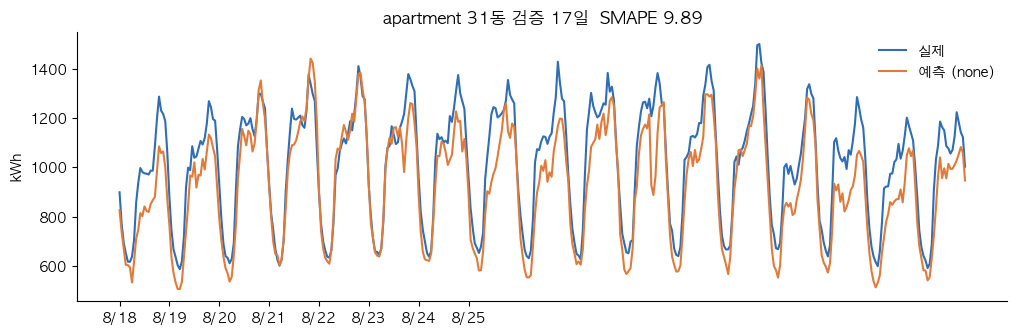

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.5))
y = valid_part.power_consumption.to_numpy()
ax.plot(range(len(y)), y, label="실제", color="#2F6DB5", lw=1.5)
ax.plot(range(len(y)), pred, label=f"예측 ({TREND})", color="#E07B39", lw=1.5)
ax.set_xticks(range(0, 169, 24)); ax.set_xticklabels([f"8/{18+i}" for i in range(7)] + ["8/25"])
ax.set_title(f"{TYPE} {BUILDING}동 검증 17일  SMAPE {gm.smape(y, pred):.2f}"); ax.set_ylabel("kWh"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); plt.show()

### 3-1. 같은 건물에서 추세 처리 4가지 비교
v1(추세 변수 그대로), none(제거), smooth(길이척도 30일 이상), linear(직선 추세 + 잔차)

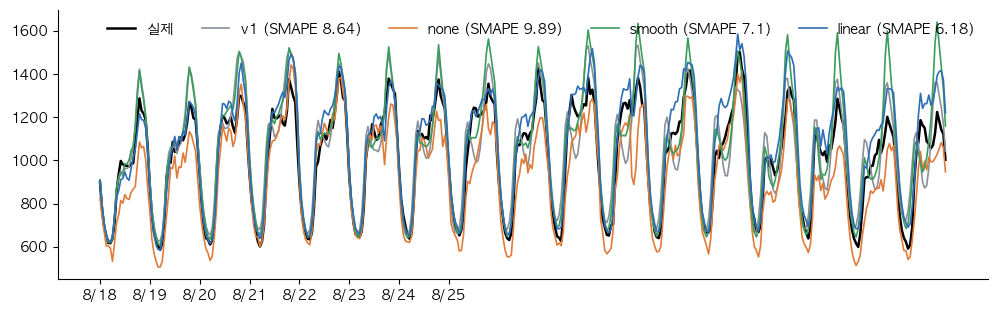

,trend,smape,mae,sec
0,v1,8.64,88.6,11
1,none,9.89,93.6,7
2,smooth,7.10,77.5,10
3,linear,6.18,66.8,8


In [8]:
rows = []
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(range(len(y)), y, label="실제", color="black", lw=1.8)
for tr, c in zip(["v1", "none", "smooth", "linear"], ["#8A8F98", "#E07B39", "#3A9D5D", "#2F6DB5"]):
    t0 = time.time()
    p, k = gm.fit_and_predict(fit_part, valid_part, gm.feature_columns(tr), tr, 0)
    rows.append(dict(trend=tr, smape=round(gm.smape(y, p), 2), mae=round(gm.mae(y, p), 1), sec=round(time.time()-t0)))
    ax.plot(range(len(y)), p, label=f"{tr} (SMAPE {rows[-1]['smape']})", color=c, lw=1.2)
ax.set_xticks(range(0, 169, 24)); ax.set_xticklabels([f"8/{18+i}" for i in range(7)] + ["8/25"])
ax.legend(frameon=False, ncol=5); ax.spines[["top", "right"]].set_visible(False); plt.show()
pd.DataFrame(rows)

## 4. 전체 기간 재학습 → test 예측
검증에서 찾은 커널 값을 고정하고 85일 전체로 다시 학습해 8/25~8/31을 예측한다. 이 값이 제출 파일에 들어간다.

In [9]:
tb = test[test.building_id == BUILDING].sort_values("num_date_time")
test_pred, _ = gm.fit_and_predict(b, tb, cols, TREND, RESTARTS, kernel=kernel)
out = pd.DataFrame({"num_date_time": tb.num_date_time.to_numpy(), "answer": np.round(test_pred, 2)})
print(out.shape); out.head()

(168, 2)


,num_date_time,answer
0,31_20240825 00,817.96
1,31_20240825 01,680.53
2,31_20240825 02,608.28
3,31_20240825 03,579.29
4,31_20240825 04,544.38


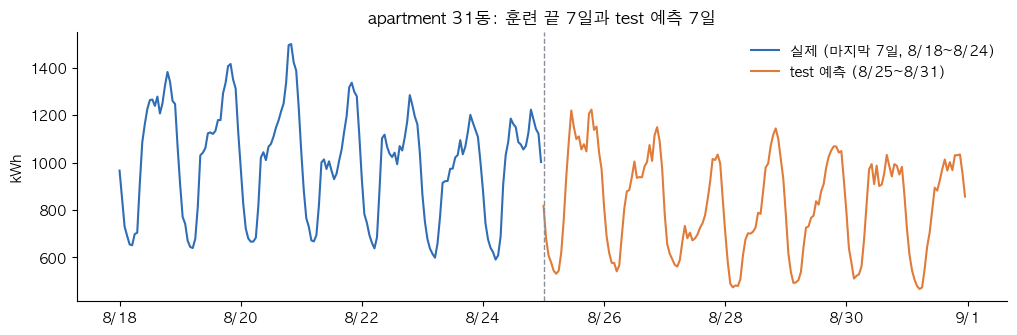

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.5))
hist = b.tail(24*7)
ax.plot(range(-168, 0), hist.power_consumption.to_numpy(), color="#2F6DB5", label="실제 (마지막 7일, 8/18~8/24)")
ax.plot(range(0, 168), test_pred, color="#E07B39", label="test 예측 (8/25~8/31)")
ax.axvline(0, color="#8A8F98", ls="--", lw=1)
ax.set_xticks(range(-168, 169, 48)); ax.set_xticklabels(["8/18", "8/20", "8/22", "8/24", "8/26", "8/28", "8/30", "9/1"])
ax.set_title(f"{TYPE} {BUILDING}동: 훈련 끝 7일과 test 예측 7일"); ax.set_ylabel("kWh"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); plt.show()

## 5. 건물유형 하나를 통째로 돌리기
`run_type`이 건물마다 위 과정을 병렬로 수행하고 결과를 `model_output/<tag>/`에 저장한다. 아파트 9동, 재시작 0회면 몇 분.
결과를 덮어쓰지 않도록 `tag="notebook_test"`로 저장한다.

In [11]:
RUN_TYPE = False          # True로 바꾸면 실행 (몇 분 소요)
if RUN_TYPE:
    out_dir = PROJECT / "model_output" / "notebook_test"
    gm.run_type(TYPE, out_dir, trend="none", restarts=0, validate_only=True, n_jobs=gm.os.cpu_count())
    pd.read_csv(out_dir / f"{TYPE}_validation.csv").drop(columns=["kernel"])

## 6. 저장된 100동 결과: v1 vs v2
`model_output/gaussian_v1/` (v1)과 `model_output/gaussian/` (v2 최종)을 읽는다.

In [12]:
NAMES = {"apartment":"아파트","commercial":"상용","department_store":"백화점","hospital":"병원","hotel":"호텔",
         "idc":"IDC(전화국)","other":"건물기타","public":"공공","research":"연구소","school":"학교"}

def load_results(tag):
    d = PROJECT / "model_output" / tag
    m = pd.concat([pd.read_csv(d / f"{t}_validation.csv").assign(type=t) for t in NAMES])
    v = pd.concat([pd.read_csv(d / f"{t}_validation_pred.csv").assign(type=t) for t in NAMES])
    return m, v

m1, v1 = load_results("gaussian_v1")
m2, v2 = load_results("gaussian")
by_type = pd.DataFrame({
    "건물 수": m2.groupby("type").size(),
    "v1 SMAPE": v1.groupby("type").apply(lambda g: gm.smape(g.actual, g.predicted)),
    "v2 SMAPE": v2.groupby("type").apply(lambda g: gm.smape(g.actual, g.predicted)),
    "v1 20이상": m1.groupby("type").apply(lambda g: (g.smape >= 20).sum()),
    "v2 20이상": m2.groupby("type").apply(lambda g: (g.smape >= 20).sum()),
}).rename(index=NAMES).round(2).sort_values("v2 SMAPE")
print(f"100동 전체 SMAPE  v1 {gm.smape(v1.actual, v1.predicted):.2f} → v2 {gm.smape(v2.actual, v2.predicted):.2f}")
by_type

100동 전체 SMAPE  v1 15.49 → v2 8.71


,건물 수,v1 SMAPE,v2 SMAPE,v1 20이상,v2 20이상
type,,,,,
IDC(전화국),9,3.20,3.26,0,0
상용,10,12.14,4.14,3,0
병원,9,13.40,4.81,1,0
학교,10,15.19,6.77,3,0
아파트,9,10.75,7.78,1,0
공공,8,18.68,9.93,3,0
연구소,9,20.67,10.44,5,1
호텔,10,13.49,10.62,2,1
백화점,16,23.70,11.36,11,0


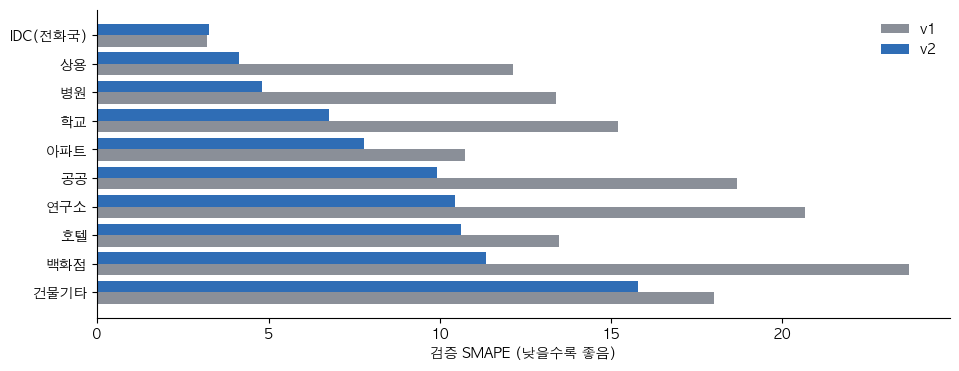

In [13]:
fig, ax = plt.subplots(figsize=(11, 4))
yy = np.arange(len(by_type))
ax.barh(yy + 0.2, by_type["v1 SMAPE"], 0.4, color="#8A8F98", label="v1")
ax.barh(yy - 0.2, by_type["v2 SMAPE"], 0.4, color="#2F6DB5", label="v2")
ax.set_yticks(yy); ax.set_yticklabels(by_type.index); ax.invert_yaxis(); ax.set_xlabel("검증 SMAPE (낮을수록 좋음)")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); plt.show()

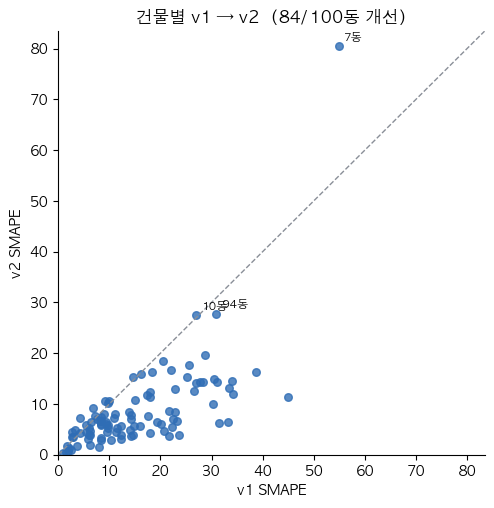

In [14]:
# 건물별 산점도: 점선 아래 = v2가 더 좋음
s1 = m1.set_index("building_id").smape; s2 = m2.set_index("building_id").smape.reindex(s1.index)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
lim = max(s1.max(), s2.max()) + 3
ax.plot([0, lim], [0, lim], "--", color="#8A8F98", lw=1)
ax.scatter(s1, s2, s=30, color="#2F6DB5", alpha=.8)
for bid in s2[s2 >= 20].index: ax.annotate(f"{bid}동", (s1[bid], s2[bid]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("v1 SMAPE"); ax.set_ylabel("v2 SMAPE"); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_title(f"건물별 v1 → v2  ({int((s2 < s1).sum())}/100동 개선)"); ax.spines[["top", "right"]].set_visible(False); plt.show()

In [15]:
# v2에서도 오차가 큰 건물 들여다보기
worst = m2.sort_values("smape", ascending=False).head(5)[["type", "building_id", "smape", "mae"]]
worst["type"] = worst["type"].map(NAMES); worst

,type,building_id,smape,mae
0,건물기타,7,80.422,3014.29
8,연구소,94,27.759,538.71
3,호텔,10,27.426,2426.93
8,백화점,54,19.586,522.49
9,호텔,100,18.445,389.84


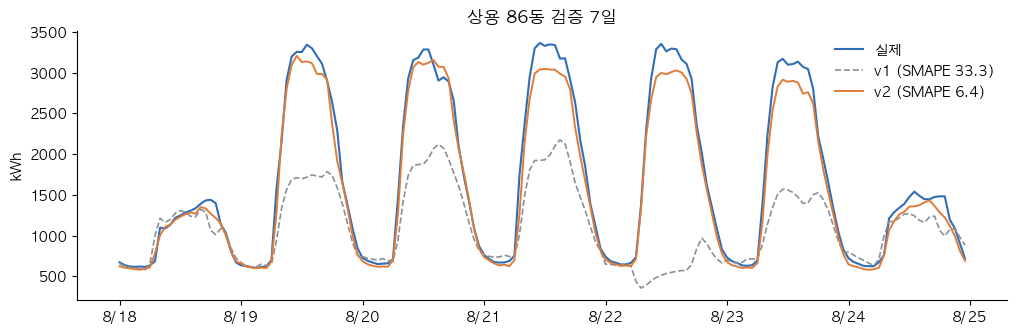

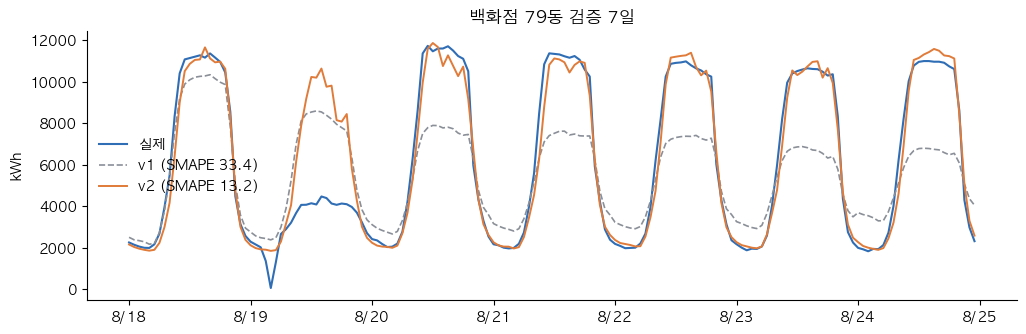

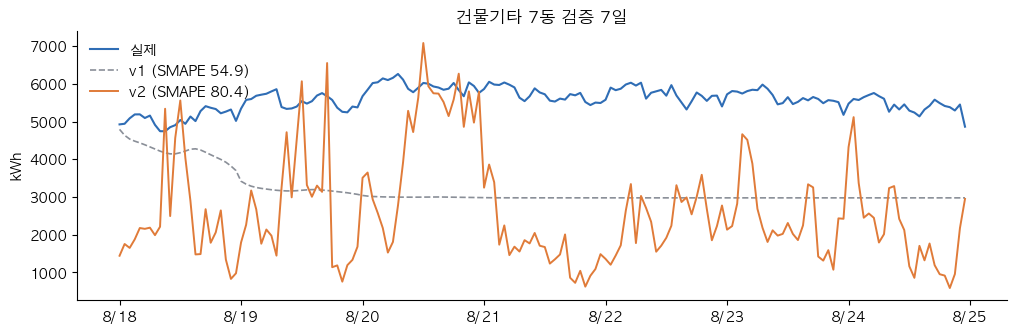

In [16]:
def show_building(btype, bid):
    a = v1[(v1.type == btype) & (v1.building_id == bid)].reset_index(drop=True)
    b_ = v2[(v2.type == btype) & (v2.building_id == bid)].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(a.index, a.actual, color="#2F6DB5", lw=1.5, label="실제")
    ax.plot(a.index, a.predicted, color="#8A8F98", ls="--", lw=1.2, label=f"v1 (SMAPE {gm.smape(a.actual, a.predicted):.1f})")
    ax.plot(b_.index, b_.predicted, color="#E07B39", lw=1.4, label=f"v2 (SMAPE {gm.smape(b_.actual, b_.predicted):.1f})")
    ax.set_xticks(range(0, 169, 24)); ax.set_xticklabels([f"8/{18+i}" for i in range(7)] + ["8/25"])
    ax.set_title(f"{NAMES[btype]} {bid}동 검증 7일"); ax.set_ylabel("kWh"); ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False); plt.show()

show_building("commercial", 86)        # 공휴일 문제가 고쳐진 사례
show_building("department_store", 79)  # 추세 변수 평균 회귀가 고쳐진 사례
show_building("other", 7)              # v2에서도 큰 오차: 8/6부터 사용량 4배 급증

## 7. 추세 처리 방식 비교 (35동)
`model_output/cmp_none`, `cmp_smooth`, `cmp_linear` (아파트·상용·백화점, 공휴일 변수 포함, 재시작 0회)

In [17]:
CMP_TYPES = ["apartment", "commercial", "department_store"]
rows = []
for tag, label in [("gaussian_v1", "v1 (기존)"), ("cmp_none", "none: 추세 제거"), ("cmp_smooth", "smooth: 길이척도 30일+"), ("cmp_linear", "linear: 직선 추세+잔차")]:
    d = PROJECT / "model_output" / tag
    v = pd.concat([pd.read_csv(d / f"{t}_validation_pred.csv").assign(type=t) for t in CMP_TYPES])
    m = pd.concat([pd.read_csv(d / f"{t}_validation.csv") for t in CMP_TYPES])
    row = {"방식": label, **{NAMES[t]: round(gm.smape(v[v.type == t].actual, v[v.type == t].predicted), 2) for t in CMP_TYPES},
           "35동 전체": round(gm.smape(v.actual, v.predicted), 2), "SMAPE 20 이상": int((m.smape >= 20).sum())}
    rows.append(row)
pd.DataFrame(rows).set_index("방식")

,아파트,상용,백화점,35동 전체,SMAPE 20 이상
방식,,,,,
v1 (기존),10.75,12.14,23.70,17.07,15
none: 추세 제거,7.78,4.14,11.36,8.38,0
smooth: 길이척도 30일+,7.83,5.45,17.97,11.78,5
linear: 직선 추세+잔차,14.34,5.78,13.05,11.31,3


## 8. 제출 파일 확인

In [18]:
sub = pd.read_csv(PROJECT / "model_output/gaussian/gaussian_submission.csv")
te = pd.read_csv(PROJECT / "raw_data/test.csv")
print("행 수", len(sub), "| 결측", sub.answer.isna().sum(), "| 음수", (sub.answer < 0).sum(), "| test 키 일치", set(te.num_date_time) == set(sub.num_date_time))
sub.head()

행 수 16800 | 결측 0 | 음수 0 | test 키 일치 True


,num_date_time,answer
0,1_20240825 00,4709.36
1,1_20240825 01,4489.18
2,1_20240825 02,4124.25
3,1_20240825 03,3816.09
4,1_20240825 04,3565.10
